In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import silhouette_samples,silhouette_score

In [3]:
pd.options.display.float_format="{:20.2f}".format
pd.set_option('display.max_columns',999)

In [4]:
df = pd.read_csv("datasetV5.csv")
df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.00,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.00,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.00,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.00,United Kingdom


In [5]:
df['Description']

0          15CM CHRISTMAS GLASS BALL 20 LIGHTS
1                           PINK CHERRY LIGHTS
2                          WHITE CHERRY LIGHTS
3                 RECORD FRAME 7" SINGLE SIZE 
4               STRAWBERRY CERAMIC TRINKET BOX
                          ...                 
1067366           CHILDREN'S APRON DOLLY GIRL 
1067367          CHILDRENS CUTLERY DOLLY GIRL 
1067368        CHILDRENS CUTLERY CIRCUS PARADE
1067369          BAKING SET 9 PIECE RETROSPOT 
1067370                                POSTAGE
Name: Description, Length: 1067371, dtype: object

In [9]:
df.describe()

,Quantity,Price,Customer ID
count,1067371.00,1067371.00,824364.00
mean,9.94,4.65,15324.64
std,172.71,123.55,1697.46
min,-80995.00,-53594.36,12346.00
25%,1.00,1.25,13975.00
50%,3.00,2.10,15255.00
75%,10.00,4.15,16797.00
max,80995.00,38970.00,18287.00


In [13]:
df[df['Customer ID'].isnull()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1066997,581498,85099B,JUMBO BAG RED RETROSPOT,5,2011-12-09 10:26:00,4.13,NaN,United Kingdom
1066998,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,2011-12-09 10:26:00,4.13,NaN,United Kingdom
1066999,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,2011-12-09 10:26:00,4.96,NaN,United Kingdom
1067000,581498,85174,S/4 CACTI CANDLES,1,2011-12-09 10:26:00,10.79,NaN,United Kingdom


In [14]:
df[df['Quantity']<0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.00,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.00,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.00,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.00,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.00,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.00,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.00,United Kingdom


In [21]:
df['Invoice'] = df['Invoice'].astype("str")

In [23]:
df[df["Invoice"].str.match("^\\d{6}$")!=True]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.00,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.00,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.00,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
...,...,...,...,...,...,...,...,...
1065910,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.00,United Kingdom
1067002,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.00,United Kingdom
1067176,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.00,United Kingdom
1067177,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.00,United Kingdom


In [25]:
df['Invoice'].str.replace("[0-9]","",regex=True).unique()

array(['', 'C', 'A'], dtype=object)

In [26]:
df[df['Invoice'].str.startswith('A')]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [28]:
df['StockCode'] = df['StockCode'].astype('str')

In [31]:
df[(df["StockCode"].str.match("^\\d{5}$")==False)&(df["StockCode"].str.match("^\\d{5}[a-zA-Z]+$")==False)]['StockCode'].unique()

array(['POST', 'D', 'DCGS0058', 'DCGS0068', 'DOT', 'M', 'DCGS0004',
       'DCGS0076', 'C2', 'BANK CHARGES', 'DCGS0003', 'TEST001',
       'gift_0001_80', 'DCGS0072', 'gift_0001_20', 'DCGS0044', 'TEST002',
       'gift_0001_10', 'gift_0001_50', 'DCGS0066N', 'gift_0001_30',
       'PADS', 'ADJUST', 'gift_0001_40', 'gift_0001_60', 'gift_0001_70',
       'gift_0001_90', 'DCGSSGIRL', 'DCGS0006', 'DCGS0016', 'DCGS0027',
       'DCGS0036', 'DCGS0039', 'DCGS0060', 'DCGS0056', 'DCGS0059', 'GIFT',
       'DCGSLBOY', 'm', 'DCGS0053', 'DCGS0062', 'DCGS0037', 'DCGSSBOY',
       'DCGSLGIRL', 'S', 'DCGS0069', 'DCGS0070', 'DCGS0075', 'B',
       'DCGS0041', 'ADJUST2', '47503J ', 'C3', 'SP1002', 'AMAZONFEE',
       'DCGS0055', 'DCGS0074', 'DCGS0057', 'DCGS0073', 'DCGS0071',
       'DCGS0066P', 'DCGS0067', 'CRUK'], dtype=object)

In [34]:
df[df["StockCode"].str.contains("^PADS")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
62299,494914,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-19 17:04:00,0.00,16705.00,United Kingdom
74731,496222,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-29 13:53:00,0.00,13583.00,United Kingdom
77702,496473,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-01 15:38:00,0.00,17350.00,United Kingdom
79794,496643,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-03 11:58:00,0.00,13408.00,United Kingdom
90798,497935,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-15 10:47:00,0.00,13408.00,United Kingdom
97716,498562,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-21 12:03:00,0.00,15182.00,United Kingdom
101718,499056,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-24 13:46:00,0.00,13765.00,United Kingdom
104480,499399,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-26 13:26:00,0.00,14459.00,United Kingdom
123947,501176,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-03-15 11:00:00,0.00,14857.00,United Kingdom
156809,504332,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-04-12 16:30:00,0.00,12671.00,Germany


In [35]:
cleaned_df = df.copy()

In [36]:
cleaned_df['Invoice'] = cleaned_df['Invoice'].astype('str')

In [37]:
mask = (
    cleaned_df["Invoice"].str.match("^\\d{6}$") == True
)
cleaned_df = cleaned_df[mask]

In [53]:
mask  = (
    (cleaned_df['StockCode'].str.match("^\\d{5}$"))
    |(cleaned_df['StockCode'].str.match("^\\d{5}[a-zA-Z]+$")==True)
    |(cleaned_df['StockCode'].str.match("^PADS$"))
)



In [54]:
cleaned_df=cleaned_df[mask]

In [60]:
cleaned_df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom
...,...,...,...,...,...,...,...,...
1067365,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.00,France
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.00,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.00,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.00,France


In [59]:
cleaned_df.describe()

,Quantity,Price,Customer ID
count,802711.00,802711.00,802711.00
mean,13.34,2.93,15338.07
std,144.54,4.28,1693.93
min,1.00,0.00,12346.00
25%,2.00,1.25,13988.00
50%,5.00,1.95,15276.00
75%,12.00,3.75,16809.00
max,80995.00,649.50,18287.00


In [58]:
cleaned_df.dropna(subset=["Customer ID"],inplace=True)

In [62]:
cleaned_df = cleaned_df[cleaned_df['Price']>0]

In [63]:
len(cleaned_df)

802649

In [70]:
(len(df)-len(cleaned_df))/len(df)

0.2480131088440664

In [71]:
fec = cleaned_df.copy()

In [74]:
cleaned_df=fec.copy()

In [75]:
cleaned_df['SalesLineTotal'] = cleaned_df["Quantity"]*cleaned_df["Price"]

In [76]:
cleaned_df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SalesLineTotal
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
1067365,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.00,France,10.20
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.00,France,12.60
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.00,France,16.60
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.00,France,16.60


In [77]:
aggregated_df = cleaned_df.groupby(by="Customer ID",as_index=False).agg(
    MonetaryValue = ("SalesLineTotal","sum"),
    Frequency = ("Invoice","nunique"),
    LastInvoiceDate =("InvoiceDate","max")
    )

In [78]:
aggregated_df

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate
0,12346.00,77352.96,3,2011-01-18 10:01:00
1,12347.00,5633.32,8,2011-12-07 15:52:00
2,12348.00,1658.40,5,2011-09-25 13:13:00
3,12349.00,3678.69,3,2011-11-21 09:51:00
4,12350.00,294.40,1,2011-02-02 16:01:00
...,...,...,...,...
5847,18283.00,2730.70,22,2011-12-06 12:02:00
5848,18284.00,411.68,1,2010-10-04 11:33:00
5849,18285.00,377.00,1,2010-02-17 10:24:00
5850,18286.00,1246.43,2,2010-08-20 11:57:00


In [87]:
max_invoice_date = aggregated_df["LastInvoiceDate"].max()

In [85]:
aggregated_df['LastInvoiceDate']=pd.to_datetime(aggregated_df['LastInvoiceDate'])

In [88]:
aggregated_df["Recency"] = (max_invoice_date-aggregated_df['LastInvoiceDate']).dt.days

In [89]:
aggregated_df

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
0,12346.00,77352.96,3,2011-01-18 10:01:00,325
1,12347.00,5633.32,8,2011-12-07 15:52:00,1
2,12348.00,1658.40,5,2011-09-25 13:13:00,74
3,12349.00,3678.69,3,2011-11-21 09:51:00,18
4,12350.00,294.40,1,2011-02-02 16:01:00,309
...,...,...,...,...,...
5847,18283.00,2730.70,22,2011-12-06 12:02:00,3
5848,18284.00,411.68,1,2010-10-04 11:33:00,431
5849,18285.00,377.00,1,2010-02-17 10:24:00,660
5850,18286.00,1246.43,2,2010-08-20 11:57:00,476


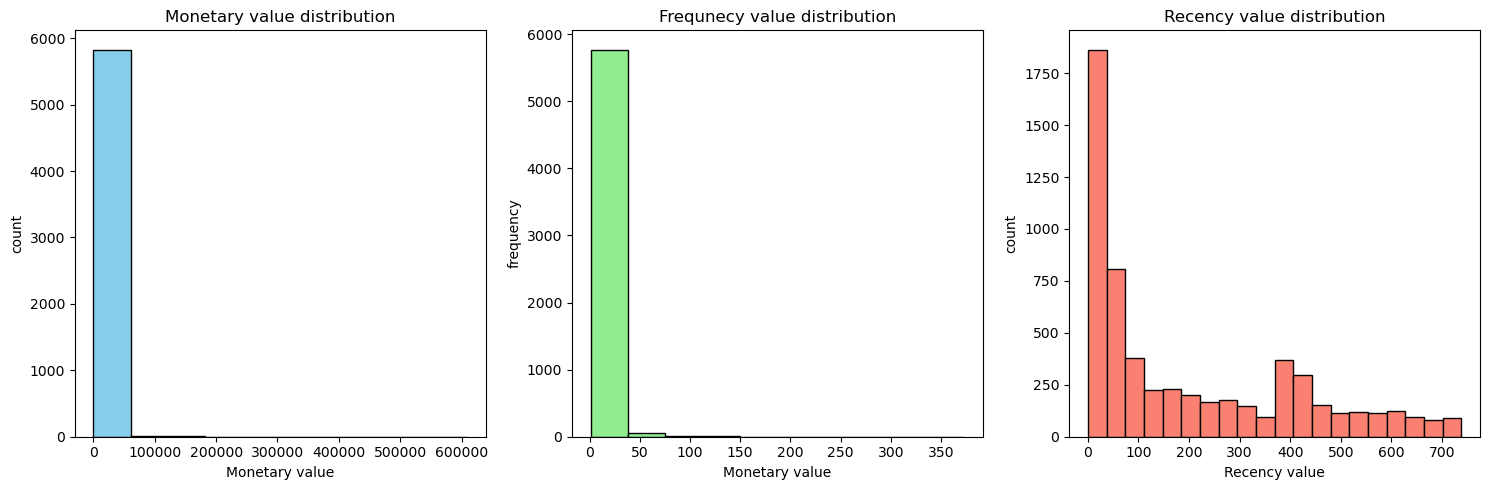

In [93]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.hist(aggregated_df["MonetaryValue"],bins=10,color='skyblue',edgecolor='black')
plt.title('Monetary value distribution')
plt.xlabel('Monetary value')
plt.ylabel('count')

plt.subplot(1,3,2)
plt.hist(aggregated_df['Frequency'],bins=10,color='lightgreen',edgecolor='black')
plt.title('Frequnecy value distribution')
plt.xlabel('Monetary value')
plt.ylabel('frequency')


plt.subplot(1,3,3)
plt.hist(aggregated_df["Recency"],bins=20,color='salmon',edgecolor='black')
plt.title('Recency value distribution')
plt.xlabel('Recency value')
plt.ylabel('count')

plt.tight_layout()
plt.show()



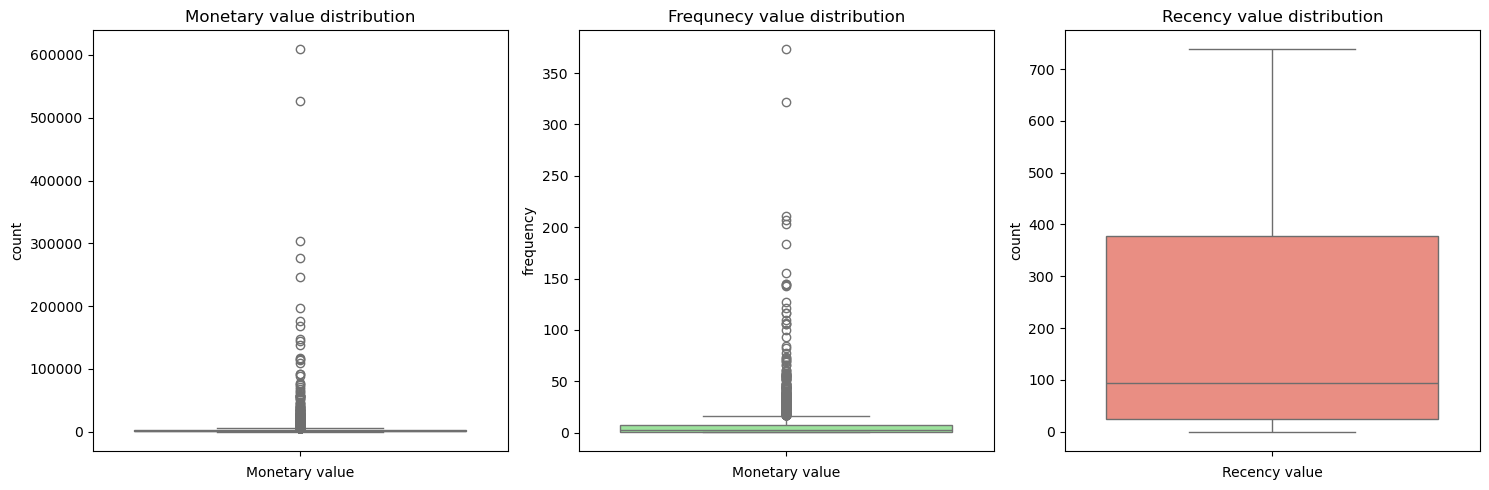

In [94]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
sns.boxplot(aggregated_df["MonetaryValue"],color='skyblue')
plt.title('Monetary value distribution')
plt.xlabel('Monetary value')
plt.ylabel('count')

plt.subplot(1,3,2)
sns.boxplot(aggregated_df['Frequency'],color='lightgreen')
plt.title('Frequnecy value distribution')
plt.xlabel('Monetary value')
plt.ylabel('frequency')


plt.subplot(1,3,3)
sns.boxplot(aggregated_df["Recency"],color='salmon')
plt.title('Recency value distribution')
plt.xlabel('Recency value')
plt.ylabel('count')

plt.tight_layout()
plt.show()



In [95]:
M_Q1 = aggregated_df['MonetaryValue'].quantile(0.25)
print(M_Q1)

344.975


In [97]:
M_Q3 = aggregated_df['MonetaryValue'].quantile(0.75)
print(M_Q3)

2289.335


In [98]:
M_IQR = M_Q3-M_Q1

In [99]:
monetary_outliers = aggregated_df[(aggregated_df['MonetaryValue']>(M_Q3+1.5*M_IQR)) | (aggregated_df['MonetaryValue']<(M_Q1+1.5*M_IQR))]

In [100]:
monetary_outliers.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
count,5420.00,5420.00,5420.00,5420,5420.00
mean,15325.05,2890.99,5.91,2011-05-14 00:14:58.206642176,209.00
min,12346.00,2.95,1.00,2009-12-01 10:49:00,0.00
25%,13836.75,322.41,1.00,2010-11-18 15:08:45,28.00
50%,15324.50,780.23,3.00,2011-08-19 00:41:00,112.00
75%,16808.25,1793.54,6.00,2011-11-11 11:34:00,385.00
max,18286.00,608821.65,373.00,2011-12-09 12:50:00,738.00
std,1714.26,15171.69,13.11,NaN,211.11


In [102]:
F_Q1 = aggregated_df['Frequency'].quantile(0.25)
F_Q3 = aggregated_df['Frequency'].quantile(0.75)
F_IQR = F_Q3-F_Q1
frequency_outliers_df = aggregated_df[(aggregated_df['Frequency']<(F_Q1+1.5*F_IQR))|(aggregated_df['Frequency']>(F_Q3+1.5*F_IQR))]

In [103]:
frequency_outliers_df

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
0,12346.00,77352.96,3,2011-01-18 10:01:00,325
1,12347.00,5633.32,8,2011-12-07 15:52:00,1
2,12348.00,1658.40,5,2011-09-25 13:13:00,74
3,12349.00,3678.69,3,2011-11-21 09:51:00,18
4,12350.00,294.40,1,2011-02-02 16:01:00,309
...,...,...,...,...,...
5847,18283.00,2730.70,22,2011-12-06 12:02:00,3
5848,18284.00,411.68,1,2010-10-04 11:33:00,431
5849,18285.00,377.00,1,2010-02-17 10:24:00,660
5850,18286.00,1246.43,2,2010-08-20 11:57:00,476


In [104]:
R_Q1 = aggregated_df['Recency'].quantile(0.25)
R_Q3 = aggregated_df['Recency'].quantile(0.75)
R_IQR = R_Q3-R_Q1
recency_outliers_df = aggregated_df[(aggregated_df['Recency']<(R_Q1<1.5*R_IQR) )|(aggregated_df['Recency']>(R_Q3+1.5*R_IQR))]

In [105]:
recency_outliers_df.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
count,93.00,93.00,93.00,93,93.00
mean,15150.87,23002.04,32.26,2011-12-08 22:51:25.161289984,0.00
min,12423.00,252.49,1.00,2011-12-08 12:52:00,0.00
25%,13471.00,1840.89,5.00,2011-12-08 14:58:00,0.00
50%,14911.00,4656.00,13.00,2011-12-08 17:54:00,0.00
75%,16892.00,11711.95,29.00,2011-12-09 10:02:00,0.00
max,18102.00,608821.65,373.00,2011-12-09 12:50:00,0.00
std,1786.52,72063.82,59.03,NaN,0.00


In [114]:
non_outliers_df = aggregated_df[~((aggregated_df.index.isin(monetary_outliers.index))|(aggregated_df.index.isin(frequency_outliers_df.index))|(aggregated_df.index.isin(recency_outliers_df.index)))]

In [119]:
monetary_outliers.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
count,5420.00,5420.00,5420.00,5420,5420.00
mean,15325.05,2890.99,5.91,2011-05-14 00:14:58.206642176,209.00
min,12346.00,2.95,1.00,2009-12-01 10:49:00,0.00
25%,13836.75,322.41,1.00,2010-11-18 15:08:45,28.00
50%,15324.50,780.23,3.00,2011-08-19 00:41:00,112.00
75%,16808.25,1793.54,6.00,2011-11-11 11:34:00,385.00
max,18286.00,608821.65,373.00,2011-12-09 12:50:00,738.00
std,1714.26,15171.69,13.11,NaN,211.11


In [116]:
frequency_outliers_df.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
count,5315.00,5315.00,5315.00,5315,5315.00
mean,15317.36,2776.58,5.64,2011-05-09 14:29:33.968015104,213.41
min,12346.00,2.95,1.00,2009-12-01 10:49:00,0.00
25%,13821.50,318.21,1.00,2010-11-15 13:18:00,29.00
50%,15323.00,758.82,3.00,2011-08-08 16:31:00,122.00
75%,16807.50,1728.49,5.00,2011-11-10 11:33:30,388.00
max,18287.00,608821.65,373.00,2011-12-09 12:50:00,738.00
std,1723.98,15250.62,13.21,NaN,211.82


In [117]:
recency_outliers_df.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
count,93.00,93.00,93.00,93,93.00
mean,15150.87,23002.04,32.26,2011-12-08 22:51:25.161289984,0.00
min,12423.00,252.49,1.00,2011-12-08 12:52:00,0.00
25%,13471.00,1840.89,5.00,2011-12-08 14:58:00,0.00
50%,14911.00,4656.00,13.00,2011-12-08 17:54:00,0.00
75%,16892.00,11711.95,29.00,2011-12-09 10:02:00,0.00
max,18102.00,608821.65,373.00,2011-12-09 12:50:00,0.00
std,1786.52,72063.82,59.03,NaN,0.00


In [118]:
aggregated_df.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
count,5852.00,5852.00,5852.00,5852,5852.00
mean,15319.71,2979.23,6.25,2011-05-23 19:33:08.971291904,199.20
min,12346.00,2.95,1.00,2009-12-01 10:49:00,0.00
25%,13837.75,344.98,1.00,2010-11-25 16:23:45,24.00
50%,15320.50,880.38,3.00,2011-09-05 15:19:30,94.00
75%,16802.25,2289.34,7.00,2011-11-14 12:55:15,378.00
max,18287.00,608821.65,373.00,2011-12-09 12:50:00,738.00
std,1714.93,14604.97,12.75,NaN,208.51


In [115]:
non_outliers_df

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
16,12362.00,4737.23,10,2011-12-06 15:40:00,2
48,12395.00,4551.27,15,2011-11-20 15:21:00,18
74,12422.00,3639.35,12,2011-09-05 09:48:00,95
204,12553.00,4104.75,12,2011-12-01 16:38:00,7
243,12594.00,4890.11,14,2011-11-02 12:20:00,37
...,...,...,...,...,...
5633,18069.00,4524.66,11,2011-11-13 16:03:00,25
5637,18073.00,3877.52,12,2011-08-17 14:02:00,113
5661,18097.00,4663.32,11,2011-12-02 11:16:00,7
5732,18168.00,3770.27,16,2011-06-16 19:21:00,175


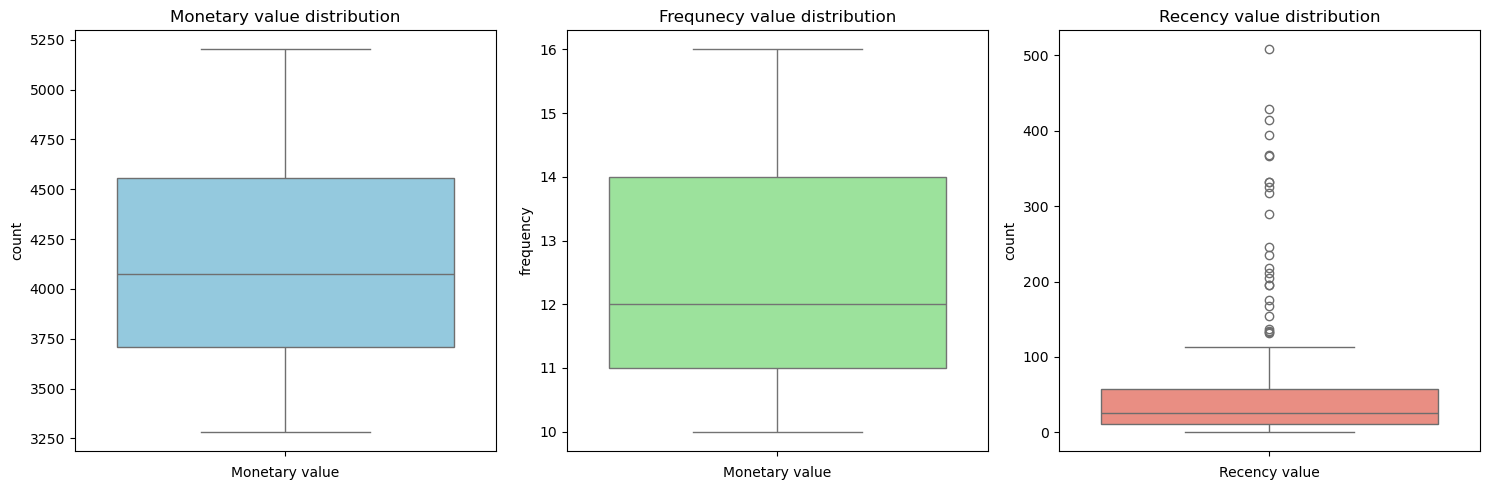

In [113]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
sns.boxplot(non_outliers_df["MonetaryValue"],color='skyblue')
plt.title('Monetary value distribution')
plt.xlabel('Monetary value')
plt.ylabel('count')

plt.subplot(1,3,2)
sns.boxplot(non_outliers_df['Frequency'],color='lightgreen')
plt.title('Frequnecy value distribution')
plt.xlabel('Monetary value')
plt.ylabel('frequency')


plt.subplot(1,3,3)
sns.boxplot(non_outliers_df["Recency"],color='salmon')
plt.title('Recency value distribution')
plt.xlabel('Recency value')
plt.ylabel('count')

plt.tight_layout()
plt.show()



In [120]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [122]:
scaled_data = scaler.fit_transform(non_outliers_df[["MonetaryValue",'Frequency','Recency']])

In [123]:
scaled_data_df = pd.DataFrame(scaled_data,index=non_outliers_df.index,columns=["MonetaryValue",'Frequency','Recency'])

In [125]:
scaled_data_df

,MonetaryValue,Frequency,Recency
16,1.10,-1.26,-0.63
48,0.76,1.56,-0.46
74,-0.93,-0.13,0.38
204,-0.07,-0.13,-0.58
243,1.39,1.00,-0.25
...,...,...,...
5633,0.71,-0.70,-0.38
5637,-0.49,-0.13,0.57
5661,0.97,-0.70,-0.58
5732,-0.69,2.13,1.24


d:\ANACONDA\a\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\ANACONDA\a\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\ANACONDA\a\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\ANACONDA\a\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than 

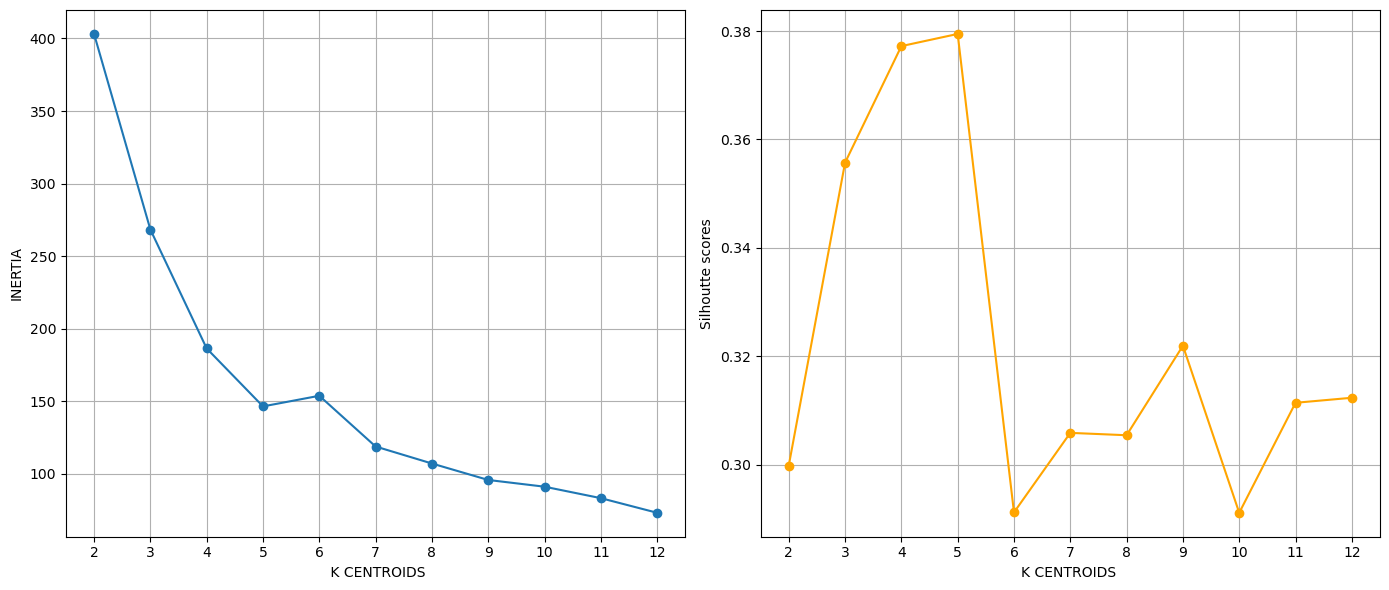

In [135]:



max_k  = 12 

inertia = []
k_values = range(2,max_k+1)
silhoutte_scores = []
for k in k_values:
    kmeans = KMeans(k,random_state=42,max_iter=1000)
    cluster_labels = kmeans.fit_predict(scaled_data_df)
    inertia.append(kmeans.inertia_)
    silhoutte_scores.append(silhouette_score(scaled_data_df,cluster_labels))

plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
plt.plot(k_values,inertia,marker = 'o')
plt.xlabel(' K CENTROIDS')
plt.ylabel('INERTIA')
plt.xticks(k_values)
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(k_values,silhoutte_scores,marker = 'o',color='orange')
plt.ylabel('Silhoutte scores')
plt.xlabel('K CENTROIDS ')
plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()
plt.show()

In [134]:
silhoutte_scores

[0.2998605029873721,
 0.3557217444537431,
 0.37721902255615747,
 0.37946340091093644,
 0.29123883689943997,
 0.3059015678499093,
 0.30546372061439925,
 0.321971632989941,
 0.29116481201582217,
 0.3114475363708909,
 0.3123745173209689]

In [136]:
kmeans = KMeans(n_clusters=4,random_state=42,max_iter=1000)
cluster_labels =kmeans.fit_predict(scaled_data_df)
cluster_labels

d:\ANACONDA\a\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([3, 1, 0, 0, 1, 0, 0, 3, 0, 0, 0, 2, 3, 1, 0, 0, 2, 1, 0, 0, 0, 1,
       0, 2, 1, 0, 3, 0, 0, 1, 0, 3, 0, 0, 1, 0, 1, 1, 1, 1, 1, 3, 0, 1,
       1, 3, 0, 3, 0, 0, 2, 3, 3, 3, 0, 0, 0, 2, 0, 0, 3, 0, 0, 2, 0, 2,
       1, 2, 1, 1, 0, 3, 0, 1, 1, 3, 1, 1, 2, 0, 3, 1, 1, 2, 3, 0, 0, 0,
       3, 3, 0, 3, 0, 3, 1, 3, 0, 0, 1, 0, 2, 3, 1, 0, 3, 0, 3, 1, 3, 0,
       0, 0, 1, 2, 0, 3, 3, 3, 0, 1, 1, 1, 1, 0, 0, 2, 1, 1, 3, 1, 3, 0,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 2, 3, 1, 0, 0, 3, 0, 3, 0, 1, 0,
       3, 1, 1, 3, 2, 2, 1, 0, 1, 3, 1, 0, 3, 1, 0, 2, 3, 1, 1, 3, 0, 1,
       3, 3, 1, 1, 1, 3, 3, 0, 3, 1, 3])

In [137]:
non_outliers_df['Cluster'] = cluster_labels

C:\Users\KJS\AppData\Local\Temp\ipykernel_23008\2548724979.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_outliers_df['Cluster'] = cluster_labels


In [138]:
non_outliers_df

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency,Cluster
16,12362.00,4737.23,10,2011-12-06 15:40:00,2,3
48,12395.00,4551.27,15,2011-11-20 15:21:00,18,1
74,12422.00,3639.35,12,2011-09-05 09:48:00,95,0
204,12553.00,4104.75,12,2011-12-01 16:38:00,7,0
243,12594.00,4890.11,14,2011-11-02 12:20:00,37,1
...,...,...,...,...,...,...
5633,18069.00,4524.66,11,2011-11-13 16:03:00,25,3
5637,18073.00,3877.52,12,2011-08-17 14:02:00,113,0
5661,18097.00,4663.32,11,2011-12-02 11:16:00,7,3
5732,18168.00,3770.27,16,2011-06-16 19:21:00,175,1
